In [1]:
# ============================================================
# CELL 1 ▸ Imports
# ============================================================
import subprocess, sys

for pkg in ['tensorflow', 'numpy', 'pandas', 'scipy',
            'matplotlib', 'seaborn', 'scikit-learn', 'tqdm']:
    imp = 'sklearn' if pkg == 'scikit-learn' else pkg
    try:
        __import__(imp)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                               '-q', pkg],
                              stdout=subprocess.DEVNULL,
                              stderr=subprocess.DEVNULL)

import os, gc, json, time, zipfile, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from scipy import stats as scipy_stats
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

tf.get_logger().setLevel('ERROR')
warnings.filterwarnings('ignore')

strategy  = tf.distribute.MirroredStrategy()
TF_GPUS   = tf.config.list_physical_devices('GPU')
N_GPUS    = strategy.num_replicas_in_sync

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300,
                     'font.size': 11, 'savefig.bbox': 'tight'})

print(f'TF {tf.__version__}  |  GPUs: {len(TF_GPUS)}')
for g in TF_GPUS: print(f'  {g}')
print(f'MirroredStrategy replicas: {N_GPUS}')
print('Imports complete.')

TF 2.20.0  |  GPUs: 2
  PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
  PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
MirroredStrategy replicas: 2
Imports complete.


I0000 00:00:1786521044.166478      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786521044.169322      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [2]:
# ============================================================
# CELL 2 ▸ Configuration
# ============================================================
# ⚙️  Change SPECS_PATH and P4A_DIR to match your Kaggle dataset paths.

# Path to specs_f16.npy (uploaded as dataset from Part 4A)
SPECS_PATH = '/kaggle/input/datasets/tarek1074/specs-f16-npy/specs_f16.npy'

# Path to part4a_results.zip extracted dataset
# (Kaggle auto-extracts zips — point to the folder containing segments.csv)
P4A_DIR    = '/kaggle/input/datasets/tarek1074/part4a-results'

SEG_CSV    = os.path.join(P4A_DIR, 'segments.csv')

WORK_DIR   = '/kaggle/working'
OUT_DIR    = os.path.join(WORK_DIR, 'part4b')
FIG_DIR    = os.path.join(OUT_DIR,  'figures')
MDL_DIR    = os.path.join(OUT_DIR,  'models')
LOG_DIR    = os.path.join(OUT_DIR,  'logs')
for d in [OUT_DIR, FIG_DIR, MDL_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

# Spectrogram / model params — must match Part 4A exactly
IMG_H, IMG_W, IMG_C = 128, 128, 3
N_FOLDS    = 5
EPOCHS     = 40
PATIENCE   = 8
LR_INIT    = 1e-3
SEED       = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

BATCH_SIZE = 32 * max(1, N_GPUS)   # 64 on 2×T4

CLASS_NAMES = [
    'Bangla_Band_Collection', 'Bangla_ancholik',
    'Bangla_baby_rhymes',     'Bangla_rabindra_sangeet',
    'Bangla_romantic',        'Classic_Songs_',
    'Islamic_Melody',         'Nazrul_Geeti_',
]
CLASS_SHORT = {
    'Bangla_Band_Collection' : 'Band',
    'Bangla_ancholik'        : 'Ancholik',
    'Bangla_baby_rhymes'     : 'Rhymes',
    'Bangla_rabindra_sangeet': 'Rabindra',
    'Bangla_romantic'        : 'Romantic',
    'Classic_Songs_'         : 'Classic',
    'Islamic_Melody'         : 'Islamic',
    'Nazrul_Geeti_'          : 'Nazrul',
}
N_CLASSES   = len(CLASS_NAMES)
SHORT_NAMES = [CLASS_SHORT[c] for c in CLASS_NAMES]
le          = LabelEncoder().fit(CLASS_NAMES)

print('Configuration loaded.')
print(f'  N_GPUS     : {N_GPUS}')
print(f'  BATCH_SIZE : {BATCH_SIZE}  ({BATCH_SIZE//max(1,N_GPUS)} per GPU)')
print(f'  SPECS_PATH : {SPECS_PATH}')
print(f'  SEG_CSV    : {SEG_CSV}')

Configuration loaded.
  N_GPUS     : 2
  BATCH_SIZE : 64  (32 per GPU)
  SPECS_PATH : /kaggle/input/datasets/tarek1074/specs-f16-npy/specs_f16.npy
  SEG_CSV    : /kaggle/input/datasets/tarek1074/part4a-results/segments.csv


In [3]:
# ============================================================
# CELL 3 ▸ Load Spectrogram Memmap + Segment Metadata
# ============================================================
# ALL_SPECS is memory-mapped — it is NOT loaded into RAM.
# Both Part 4B and Part 4C can read the same file simultaneously.

print('Loading spectrogram memmap ...')
assert os.path.exists(SPECS_PATH), (
    f'specs_f16.npy not found at {SPECS_PATH}\n'
    f'Check that you added the specs dataset to this notebook.')

ALL_SPECS = np.load(SPECS_PATH, mmap_mode='r')
print(f'  ALL_SPECS : {ALL_SPECS.shape}  dtype={ALL_SPECS.dtype}  '
      f'({ALL_SPECS.nbytes/1e9:.2f} GB memory-mapped)')

# Validate: sample 50 specs and check non-zero
rng_check = np.random.RandomState(42)
sample_i  = rng_check.choice(ALL_SPECS.shape[0], 50, replace=False)
n_nz      = sum(1 for i in sample_i if np.abs(ALL_SPECS[i]).max() > 1e-6)
assert n_nz >= 40, (
    f'Only {n_nz}/50 non-zero specs — specs_f16.npy may be corrupted.')
print(f'  Validity check: {n_nz}/50 non-zero ✅')

print('\nLoading segments.csv ...')
assert os.path.exists(SEG_CSV), (
    f'segments.csv not found at {SEG_CSV}\n'
    f'Check that part4a_results.zip was added and extracted.')

seg_df = pd.read_csv(SEG_CSV)
print(f'  {len(seg_df):,} segments  |  columns: {list(seg_df.columns)}')

# Verify alignment
assert len(seg_df) == ALL_SPECS.shape[0], (
    f'Row count mismatch: segments.csv={len(seg_df)} '
    f'but specs has {ALL_SPECS.shape[0]} rows')

ALL_LABELS = seg_df['label_id'].values.astype(np.int32)
ALL_FOLDS  = seg_df['fold'].values.astype(np.int32)
ALL_LBLSTR = seg_df['label'].values
N_SEGS     = len(seg_df)

print(f'\nSegment/fold summary:')
for k in range(N_FOLDS):
    sub = seg_df[seg_df['fold'] == k]
    n_cls = sub['label'].nunique()
    print(f'  Fold {k}: {len(sub):,} segs  |  '
          f'{sub["filepath"].nunique():,} files  |  {n_cls}/8 classes')

all_ok = all(seg_df[seg_df['fold']==k]['label'].nunique() == N_CLASSES
             for k in range(N_FOLDS))
print('✅ All 8 classes in every fold.' if all_ok
      else '⚠️  Some folds missing classes!')

Loading spectrogram memmap ...
  ALL_SPECS : (60579, 128, 128, 3)  dtype=float16  (5.96 GB memory-mapped)
  Validity check: 50/50 non-zero ✅

Loading segments.csv ...
  60,579 segments  |  columns: ['filepath', 'label', 'label_id', 'fold', 'seg_idx', 'offset_s']

Segment/fold summary:
  Fold 0: 11,609 segs  |  374 files  |  8/8 classes
  Fold 1: 12,922 segs  |  374 files  |  8/8 classes
  Fold 2: 11,769 segs  |  374 files  |  8/8 classes
  Fold 3: 13,630 segs  |  374 files  |  8/8 classes
  Fold 4: 10,649 segs  |  374 files  |  8/8 classes
✅ All 8 classes in every fold.


In [4]:
# ============================================================
# CELL 4 ▸ Data Pipeline  (identical to Part 4A)
# ============================================================
# sample_weight is the 3rd element (x, y, w) in train dataset.
# model.fit() has NO class_weight argument.

def make_sw(label_strings):
    """W2 sqrt-inverse-frequency sample weights, mean-normalised."""
    counts = np.array([(label_strings == c).sum()
                       for c in CLASS_NAMES], dtype=np.float64)
    w = np.sqrt(counts.max() / (counts + 1e-8))
    w = (w / w.mean()).astype(np.float32)
    d = {cls: float(w[i]) for i, cls in enumerate(CLASS_NAMES)}
    return np.array([d[s] for s in label_strings], dtype=np.float32)


def spec_aug(x):
    """SpecAugment: random time + frequency masking."""
    t  = tf.random.uniform((), 1, 31, dtype=tf.int32)
    t0 = tf.random.uniform((), 0, IMG_W - t, dtype=tf.int32)
    ti = tf.range(IMG_W)
    tm = tf.cast(tf.logical_or(ti < t0, ti >= t0 + t), tf.float32)
    x  = x * tm[tf.newaxis, :, tf.newaxis]
    f  = tf.random.uniform((), 1, 17, dtype=tf.int32)
    f0 = tf.random.uniform((), 0, IMG_H - f, dtype=tf.int32)
    fi = tf.range(IMG_H)
    fm = tf.cast(tf.logical_or(fi < f0, fi >= f0 + f), tf.float32)
    return x * fm[:, tf.newaxis, tf.newaxis]


def build_train_ds(gidx, lids, lbls, bs, augment=True):
    """Training dataset: yields (spec_f32, y_onehot, sample_weight)."""
    _i = np.asarray(gidx, np.int64)
    _l = np.asarray(lids,  np.int32)
    _w = make_sw(lbls)
    n  = len(_i)

    def _load(pos):
        p = int(pos)
        return ALL_SPECS[_i[p]].astype(np.float32), _l[p], _w[p]

    ds = tf.data.Dataset.range(n)
    ds = ds.shuffle(min(10_000, n), seed=SEED,
                    reshuffle_each_iteration=True)
    ds = ds.map(
        lambda p: tf.numpy_function(
            _load, [p], [tf.float32, tf.int32, tf.float32]),
        num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(
        lambda x, y, w: (
            tf.ensure_shape(x, [IMG_H, IMG_W, IMG_C]),
            tf.ensure_shape(y, []),
            tf.ensure_shape(w, [])),
        num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.map(lambda x, y, w: (spec_aug(x), y, w),
                    num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(
        lambda x, y, w: (x, tf.one_hot(y, N_CLASSES), w),
        num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs).prefetch(4)       # prefetch=4, not AUTOTUNE


def build_val_ds(gidx, lids, bs):
    """Validation dataset: yields (spec_f32, y_onehot) — no weights."""
    _i = np.asarray(gidx, np.int64)
    _l = np.asarray(lids,  np.int32)
    n  = len(_i)

    def _load(pos):
        p = int(pos)
        return ALL_SPECS[_i[p]].astype(np.float32), _l[p]

    ds = tf.data.Dataset.range(n)
    ds = ds.map(
        lambda p: tf.numpy_function(
            _load, [p], [tf.float32, tf.int32]),
        num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(
        lambda x, y: (
            tf.ensure_shape(x, [IMG_H, IMG_W, IMG_C]),
            tf.one_hot(tf.ensure_shape(y, []), N_CLASSES)),
        num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs).prefetch(2)       # prefetch=2


def predict_batched(model, gidx, bs=256):
    """Run inference in small batches to avoid OOM."""
    n   = len(gidx)
    out = np.zeros((n, N_CLASSES), dtype=np.float32)
    for s in range(0, n, bs):
        e       = min(s + bs, n)
        batch   = ALL_SPECS[gidx[s:e]].astype(np.float32)
        out[s:e] = model.predict(batch, verbose=0)
    return out


print('Data pipeline ready.')
print('  Training dataset : (spec, y_onehot, sample_weight)  prefetch=4')
print('  Validation dataset: (spec, y_onehot)                prefetch=2')
print('  model.fit() : NO class_weight  (weights are in dataset)')

Data pipeline ready.
  Training dataset : (spec, y_onehot, sample_weight)  prefetch=4
  Validation dataset: (spec, y_onehot)                prefetch=2
  model.fit() : NO class_weight  (weights are in dataset)


In [5]:
# ============================================================
# CELL 5 ▸ ResNet-CNN2D Architecture + MacroF1Callback
# ============================================================
# ResNet-style skip connections allow much deeper training
# without vanishing gradients.
# Architecture: stem → 3 residual stages → GAP → Dense(8)

def res_block(x, filters, downsample=False):
    """Basic residual block with optional downsampling."""
    sc = x
    s  = 2 if downsample else 1

    x  = layers.Conv2D(filters, (3, 3), strides=s, padding='same',
                       use_bias=False,
                       kernel_regularizer=regularizers.l2(1e-4))(x)
    x  = layers.BatchNormalization()(x)
    x  = layers.Activation('relu')(x)

    x  = layers.Conv2D(filters, (3, 3), padding='same',
                       use_bias=False,
                       kernel_regularizer=regularizers.l2(1e-4))(x)
    x  = layers.BatchNormalization()(x)

    # Shortcut projection when dimensions change
    if downsample or sc.shape[-1] != filters:
        sc = layers.Conv2D(filters, (1, 1), strides=s,
                           padding='same', use_bias=False)(sc)
        sc = layers.BatchNormalization()(sc)

    x = layers.Add()([x, sc])
    x = layers.Activation('relu')(x)
    return x


def build_resnet(n_cls=N_CLASSES):
    inp = keras.Input(shape=(IMG_H, IMG_W, IMG_C))

    # Stem
    x = layers.Conv2D(64, (7, 7), strides=2, padding='same',
                      use_bias=False,
                      kernel_regularizer=regularizers.l2(1e-4))(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D((3, 3), strides=2, padding='same')(x)

    # Residual stages
    for filters, downsample in [
        (64,  False), (64,  False),
        (128, True),  (128, False),
        (256, True),  (256, False),
        (512, True),  (512, False),
    ]:
        x = res_block(x, filters, downsample=downsample)
        x = layers.Dropout(0.1)(x)

    x   = layers.GlobalAveragePooling2D()(x)
    x   = layers.Dropout(0.4)(x)
    out = layers.Dense(n_cls, activation='softmax',
                       dtype='float32')(x)
    return keras.Model(inp, out, name='ResNet_CNN2D')


# ── MacroF1 early-stopping callback ──────────────────────────
class MacroF1CB(keras.callbacks.Callback):
    def __init__(self, val_idx, val_lids, patience=PATIENCE):
        super().__init__()
        self.vi       = np.asarray(val_idx,  np.int64)
        self.vl       = np.asarray(val_lids, np.int32)
        self.patience = patience
        self.best     = 0.0
        self.best_w   = None
        self.wait     = 0
        self.best_ep  = 0
        self.history  = []

    def on_epoch_end(self, epoch, logs=None):
        probs = predict_batched(self.model, self.vi)
        ypred = probs.argmax(axis=1)
        f1    = float(f1_score(self.vl, ypred,
                               average='macro', zero_division=0))
        self.history.append(f1)

        if f1 > self.best:
            self.best    = f1
            self.best_w  = self.model.get_weights()
            self.best_ep = epoch + 1
            self.wait    = 0
        else:
            self.wait += 1

        if self.wait >= self.patience:
            self.model.stop_training = True
            if self.best_w is not None:
                self.model.set_weights(self.best_w)

        if (epoch + 1) % 5 == 0:
            print(f'  ep {epoch+1:3d}  val_f1={f1:.4f}'
                  f'  best={self.best:.4f}@ep{self.best_ep}')


print(f'ResNet-CNN2D params: {build_resnet().count_params():,}')

ResNet-CNN2D params: 11,190,216


In [6]:
# ============================================================
# CELL 6 ▸ ResNet-CNN2D — 5-Fold Song-Disjoint CV
# ============================================================
# sample_weight embedded in ds_tr — NO class_weight in model.fit()

print('='*55)
print('  ResNet-CNN2D — 5-Fold Song-Disjoint CV')
print('='*55)
print()

resnet_metrics = []
best_res_f1    = -1.0
CV_RESULTS     = {}

for k in range(N_FOLDS):
    t0      = time.time()
    tr_mask = ALL_FOLDS != k
    te_mask = ALL_FOLDS == k

    tr_gi   = np.where(tr_mask)[0]
    te_gi   = np.where(te_mask)[0]
    y_tr    = ALL_LABELS[tr_mask]

    # Stratified 10% val from training fold
    sss = StratifiedShuffleSplit(n_splits=1, test_size=0.1,
                                  random_state=SEED + k)
    loc_tr, loc_vl = next(sss.split(tr_gi, y_tr))
    trn_gi = tr_gi[loc_tr]
    val_gi = tr_gi[loc_vl]

    ds_tr = build_train_ds(trn_gi, ALL_LABELS[trn_gi],
                            ALL_LBLSTR[trn_gi],
                            BATCH_SIZE, augment=True)
    ds_vl = build_val_ds(val_gi, ALL_LABELS[val_gi],
                          BATCH_SIZE * 2)

    f1cb  = MacroF1CB(val_gi, ALL_LABELS[val_gi])
    lrcb  = keras.callbacks.ReduceLROnPlateau(
                monitor='val_loss', factor=0.5, patience=7,
                min_lr=1e-6, verbose=0)
    logcb = keras.callbacks.CSVLogger(
                os.path.join(LOG_DIR, f'resnet_fold{k}.csv'))

    keras.backend.clear_session()
    with strategy.scope():
        model = build_resnet()
        model.compile(
            optimizer=keras.optimizers.Adam(LR_INIT),
            loss='categorical_crossentropy',
            metrics=['accuracy'])

    # ── sample_weight in ds_tr — NO class_weight here ────────
    model.fit(ds_tr,
              validation_data=ds_vl,
              epochs=EPOCHS,
              callbacks=[f1cb, lrcb, logcb],
              verbose=0)
    # ─────────────────────────────────────────────────────────

    probs  = predict_batched(model, te_gi)
    y_pred = probs.argmax(axis=1)
    y_te   = ALL_LABELS[te_mask]

    mf1  = float(f1_score(y_te, y_pred, average='macro',    zero_division=0))
    wf1  = float(f1_score(y_te, y_pred, average='weighted', zero_division=0))
    acc  = float(accuracy_score(y_te, y_pred))
    pcf1 = [float(f1_score((y_te==i).astype(int),
                            (y_pred==i).astype(int), zero_division=0))
            for i in range(N_CLASSES)]

    resnet_metrics.append({
        'macro_f1'    : mf1,
        'weighted_f1' : wf1,
        'accuracy'    : acc,
        'per_class_f1': pcf1,
        'best_epoch'  : f1cb.best_ep,
        'f1_history'  : f1cb.history,
        'y_pred'      : y_pred.tolist(),
        'y_true'      : y_te.tolist(),
    })

    if mf1 > best_res_f1:
        best_res_f1 = mf1
        model.save(os.path.join(MDL_DIR, 'resnet_cnn2d.keras'))

    elapsed = time.time() - t0
    print(f'  Fold {k+1}/5  Macro-F1={mf1:.4f}  '
          f'Acc={acc:.4f}  best_ep={f1cb.best_ep}  '
          f'({elapsed/60:.1f} min)')
    del model; gc.collect()

# ── Summary statistics ────────────────────────────────────────
mf1s = np.array([m['macro_f1'] for m in resnet_metrics])
t95  = scipy_stats.t.ppf(0.975, df=N_FOLDS - 1)
ci   = float(t95 * mf1s.std(ddof=1) / np.sqrt(N_FOLDS))

res_sum = {
    'model'             : 'ResNet_CNN2D',
    'n_folds'           : N_FOLDS,
    'macro_f1_mean'     : round(float(mf1s.mean()), 4),
    'macro_f1_std'      : round(float(mf1s.std(ddof=1)), 4),
    'macro_f1_ci95'     : round(ci, 4),
    'macro_f1_min'      : round(float(mf1s.min()), 4),
    'macro_f1_max'      : round(float(mf1s.max()), 4),
    'weighted_f1_mean'  : round(float(np.mean([m['weighted_f1']
                                               for m in resnet_metrics])), 4),
    'accuracy_mean'     : round(float(np.mean([m['accuracy']
                                               for m in resnet_metrics])), 4),
    'per_fold_macro_f1' : mf1s.tolist(),
}
CV_RESULTS['ResNet_CNN2D'] = {
    'summary'     : res_sum,
    'fold_metrics': resnet_metrics,
}

m, s, c = (res_sum['macro_f1_mean'],
            res_sum['macro_f1_std'],
            res_sum['macro_f1_ci95'])
print()
print(f'  ResNet-CNN2D  Macro-F1 : {m:.4f} +/- {s:.4f}')
print(f'  95% CI (t-dist, df=4)  : [{m-c:.4f}, {m+c:.4f}]')
print(f'  Per fold               : {[round(v,4) for v in mf1s.tolist()]}')
print(f'  Best model saved       : models/resnet_cnn2d.keras')

# Compare with VGG
vgg_f1 = 0.7702
delta  = m - vgg_f1
print()
print(f'  VGG-CNN2D baseline : {vgg_f1:.4f}')
print(f'  ResNet improvement : {delta:+.4f}  '
      f'({"ResNet wins" if delta > 0 else "VGG wins"})')

  ResNet-CNN2D — 5-Fold Song-Disjoint CV



E0000 00:00:1786521058.657709      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/ResNet_CNN2D_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.7465  best=0.7510@ep3
  ep  10  val_f1=0.7728  best=0.8101@ep8
  ep  15  val_f1=0.8437  best=0.8437@ep15
  ep  20  val_f1=0.8801  best=0.8870@ep18
  ep  25  val_f1=0.8898  best=0.8898@ep25
  ep  30  val_f1=0.9017  best=0.9049@ep29
  ep  35  val_f1=0.8963  best=0.9202@ep32
  ep  40  val_f1=0.8843  best=0.9248@ep36
  Fold 1/5  Macro-F1=0.6839  Acc=0.7128  best_ep=36  (52.5 min)


E0000 00:00:1786524206.162186      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/ResNet_CNN2D_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.6905  best=0.7029@ep4
  ep  10  val_f1=0.7935  best=0.8268@ep8
  ep  15  val_f1=0.8212  best=0.8543@ep12
  ep  20  val_f1=0.8528  best=0.8645@ep19
  ep  25  val_f1=0.8585  best=0.8816@ep22
  ep  30  val_f1=0.8395  best=0.9020@ep28
  ep  35  val_f1=0.8804  best=0.9114@ep34
  ep  40  val_f1=0.8710  best=0.9114@ep34
  Fold 2/5  Macro-F1=0.6620  Acc=0.6826  best_ep=34  (50.6 min)


...

  ep   5  val_f1=0.7914  best=0.7914@ep5
  ep  10  val_f1=0.7424  best=0.8212@ep9
  ep  15  val_f1=0.8821  best=0.8821@ep15
  ep  20  val_f1=0.8805  best=0.8924@ep18
  ep  25  val_f1=0.8829  best=0.8924@ep18
  ep  30  val_f1=0.9273  best=0.9369@ep26
  Fold 3/5  Macro-F1=0.7524  Acc=0.7731  best_ep=26  (44.2 min)


E0000 00:00:1786529895.495244      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/ResNet_CNN2D_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.4930  best=0.7461@ep3
  ep  10  val_f1=0.8161  best=0.8161@ep10
  ep  15  val_f1=0.8622  best=0.8622@ep15
  ep  20  val_f1=0.8633  best=0.8847@ep19
  ep  25  val_f1=0.8576  best=0.8847@ep19
  ep  30  val_f1=0.8749  best=0.9175@ep29
  ep  35  val_f1=0.8640  best=0.9175@ep29
  ep  40  val_f1=0.9432  best=0.9472@ep38
  Fold 4/5  Macro-F1=0.7257  Acc=0.7602  best_ep=38  (50.2 min)


E0000 00:00:1786532906.992796      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/ResNet_CNN2D_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.7217  best=0.7244@ep4
  ep  10  val_f1=0.8078  best=0.8178@ep8
  ep  15  val_f1=0.8758  best=0.8758@ep15
  ep  20  val_f1=0.8598  best=0.8758@ep15
  ep  25  val_f1=0.8703  best=0.8988@ep23
  ep  30  val_f1=0.6419  best=0.8988@ep23
  ep  35  val_f1=0.9384  best=0.9389@ep33
  ep  40  val_f1=0.9158  best=0.9414@ep37
  Fold 5/5  Macro-F1=0.7186  Acc=0.7327  best_ep=37  (52.9 min)

  ResNet-CNN2D  Macro-F1 : 0.7086 +/- 0.0357
  95% CI (t-dist, df=4)  : [0.6643, 0.7529]
  Per fold               : [0.6839, 0.662, 0.7524, 0.7257, 0.7186]
  Best model saved       : models/resnet_cnn2d.keras

  VGG-CNN2D baseline : 0.7702
  ResNet improvement : -0.0616  (VGG wins)


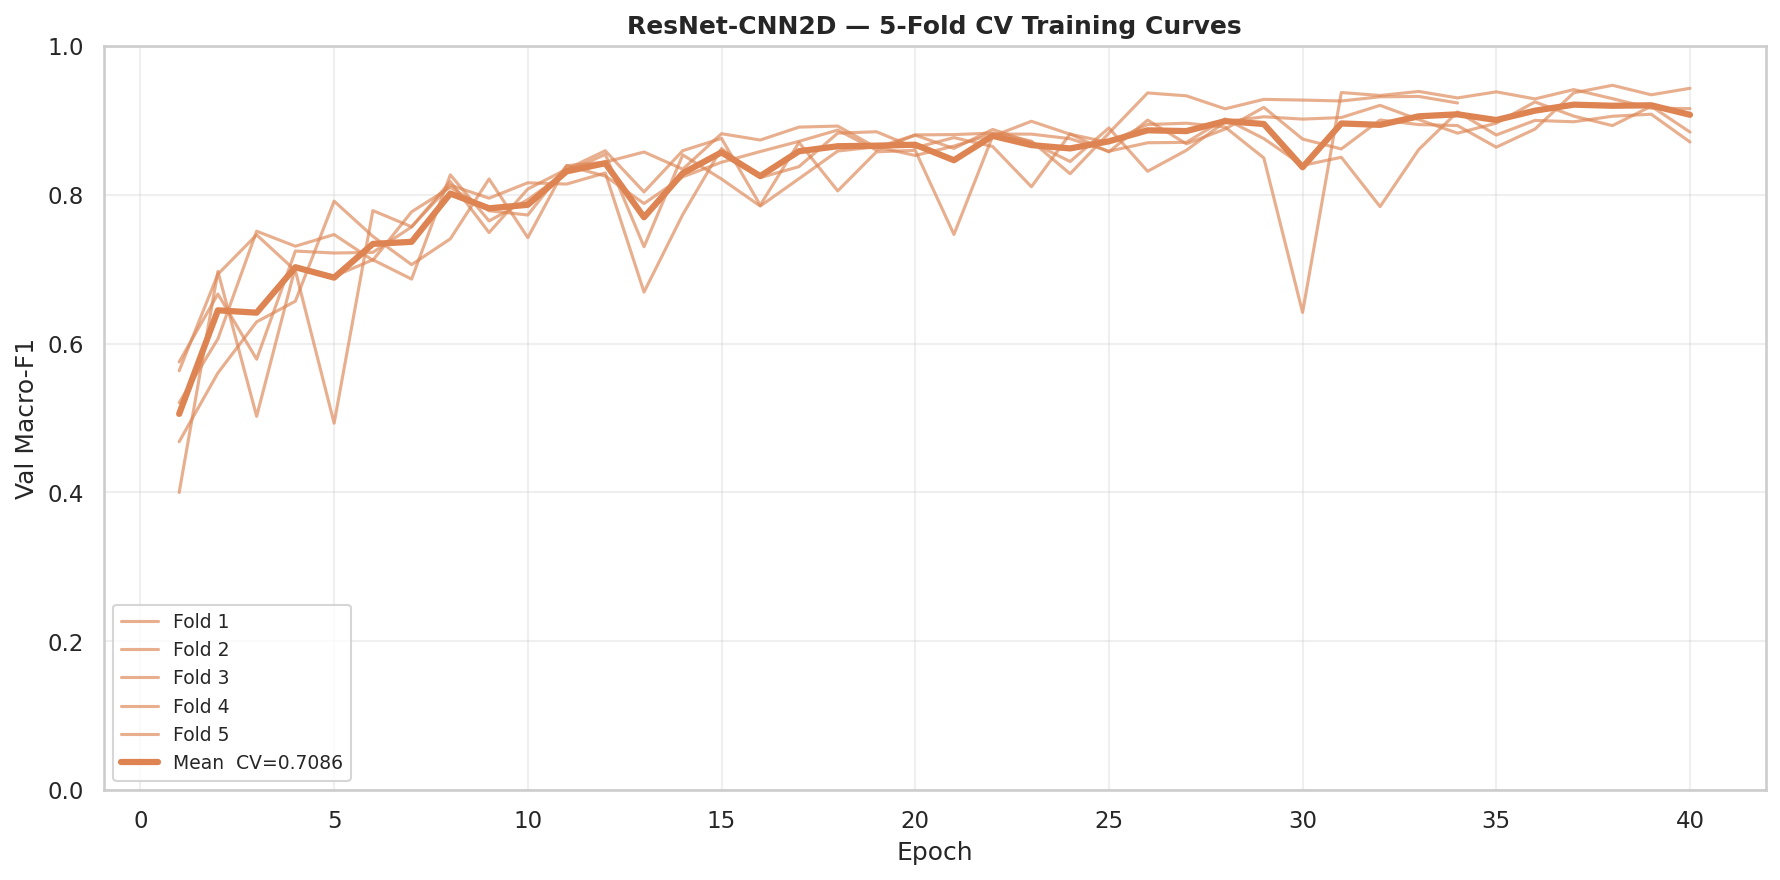

Saved: /kaggle/working/part4b/figures/resnet_training_curves.png


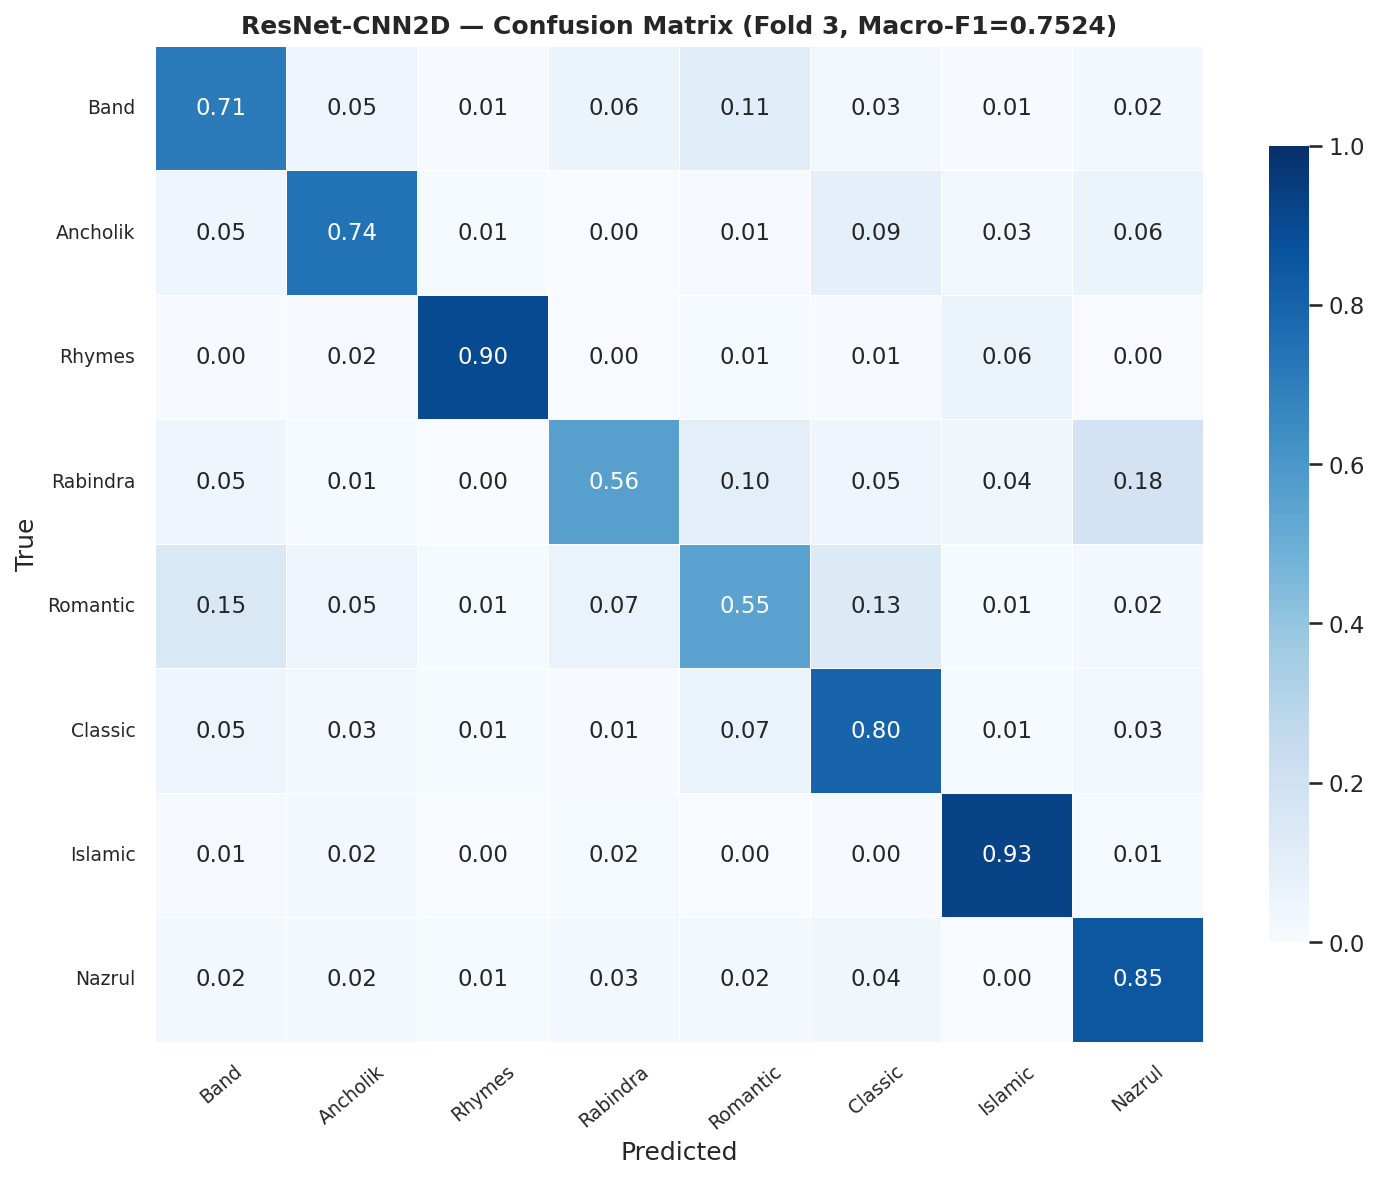

Saved: /kaggle/working/part4b/figures/resnet_confusion_matrix.png
Saved: /kaggle/working/part4b/resnet_cv_results.json

Per-class Macro-F1 (mean ± std across 5 folds):
  Class             Mean     ±Std      Min      Max
  ------------  --------  -------  -------  -------
  Band            0.6634   0.0425   0.6019   0.7172
  Ancholik        0.6278   0.0486   0.5790   0.7067
  Rhymes          0.8551   0.0812   0.7380   0.9397
  Rabindra        0.5413   0.0442   0.4842   0.5765
  Romantic        0.5415   0.0566   0.4712   0.5902
  Classic         0.7131   0.0508   0.6385   0.7578
  Islamic         0.8738   0.0627   0.7722   0.9245
  Nazrul          0.8525   0.0201   0.8184   0.8660

Creating /kaggle/working/part4b_results.zip ...
  + models/resnet_cnn2d.keras  134.5 MB
  + resnet_cv_results.json
  + logs/ (5 files)
  + figures/resnet_confusion_matrix.png
  + figures/resnet_training_curves.png

  PART 4B COMPLETE
  ResNet-CNN2D : 0.7086 +/- 0.0357  95%CI [0.6643, 0.7529]
  ZIP          : /

In [7]:
# ============================================================
# CELL 7 ▸ Training Curve Figure + Save + ZIP
# ============================================================

# ── Training curve ────────────────────────────────────────────
all_h = [m['f1_history'] for m in CV_RESULTS['ResNet_CNN2D']['fold_metrics']]
max_l = max(len(h) for h in all_h)

fig, ax = plt.subplots(figsize=(12, 6))
for k, h in enumerate(all_h):
    ax.plot(range(1, len(h)+1), h, lw=1.5, alpha=0.65,
            color='#DD8452', label=f'Fold {k+1}')

padded = [h + [h[-1]] * (max_l - len(h)) for h in all_h]
mean_h = np.mean(padded, axis=0)
ax.plot(range(1, max_l+1), mean_h, lw=3, color='#DD8452',
        label=f'Mean  CV={res_sum["macro_f1_mean"]:.4f}')

ax.set_xlabel('Epoch')
ax.set_ylabel('Val Macro-F1')
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
ax.set_title('ResNet-CNN2D — 5-Fold CV Training Curves', fontweight='bold')
plt.tight_layout()
fig_path = os.path.join(FIG_DIR, 'resnet_training_curves.png')
plt.savefig(fig_path)
plt.show()
print(f'Saved: {fig_path}')

# ── Confusion matrix (best fold) ─────────────────────────────
best_k  = int(np.argmax(mf1s))
best_fm = CV_RESULTS['ResNet_CNN2D']['fold_metrics'][best_k]
y_te_b  = np.array(best_fm['y_true'])
y_pr_b  = np.array(best_fm['y_pred'])

cm   = confusion_matrix(y_te_b, y_pr_b, labels=list(range(N_CLASSES)))
with np.errstate(divide='ignore', invalid='ignore'):
    cm_n = np.where(cm.sum(1, keepdims=True) == 0, 0,
                    cm.astype(float) / cm.sum(1, keepdims=True))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_n, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=SHORT_NAMES, yticklabels=SHORT_NAMES,
            linewidths=0.4, cbar_kws={'shrink': 0.8},
            ax=ax, vmin=0, vmax=1)
ax.set_title(f'ResNet-CNN2D — Confusion Matrix (Fold {best_k+1}, '
             f'Macro-F1={mf1s[best_k]:.4f})',
             fontweight='bold')
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.tick_params(axis='x', rotation=40, labelsize=9)
ax.tick_params(axis='y', rotation=0,  labelsize=9)
plt.tight_layout()
cm_path = os.path.join(FIG_DIR, 'resnet_confusion_matrix.png')
plt.savefig(cm_path)
plt.show()
print(f'Saved: {cm_path}')

# ── Save JSON ─────────────────────────────────────────────────
def to_py(obj):
    if isinstance(obj, dict):           return {k: to_py(v) for k,v in obj.items()}
    if isinstance(obj, (list, tuple)):  return [to_py(v) for v in obj]
    if isinstance(obj, np.ndarray):     return obj.tolist()
    if isinstance(obj, (np.integer,)):  return int(obj)
    if isinstance(obj, (np.floating,)): return float(obj)
    if isinstance(obj, (np.bool_,)):    return bool(obj)
    return obj

result_json = os.path.join(OUT_DIR, 'resnet_cv_results.json')
with open(result_json, 'w') as f:
    json.dump(to_py(CV_RESULTS), f, indent=2)
print(f'Saved: {result_json}')

# ── Per-class F1 table ────────────────────────────────────────
print()
print('Per-class Macro-F1 (mean ± std across 5 folds):')
print(f'  {"Class":<12}  {"Mean":>8}  {"±Std":>7}  {"Min":>7}  {"Max":>7}')
print(f'  {"-"*12}  {"-"*8}  {"-"*7}  {"-"*7}  {"-"*7}')
for i, cls in enumerate(SHORT_NAMES):
    vals = [m['per_class_f1'][i] for m in resnet_metrics]
    print(f'  {cls:<12}  {np.mean(vals):>8.4f}  '
          f'{np.std(vals,ddof=1):>7.4f}  '
          f'{min(vals):>7.4f}  {max(vals):>7.4f}')

# ── ZIP part4b_results ────────────────────────────────────────
zip_path = os.path.join(WORK_DIR, 'part4b_results.zip')
print(f'\nCreating {zip_path} ...')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    # Model
    m_path = os.path.join(MDL_DIR, 'resnet_cnn2d.keras')
    if os.path.exists(m_path):
        zf.write(m_path, 'models/resnet_cnn2d.keras')
        sz = os.path.getsize(m_path)/1e6
        print(f'  + models/resnet_cnn2d.keras  {sz:.1f} MB')
    # JSON
    zf.write(result_json, 'resnet_cv_results.json')
    print(f'  + resnet_cv_results.json')
    # Logs
    for fname in sorted(os.listdir(LOG_DIR)):
        fp = os.path.join(LOG_DIR, fname)
        zf.write(fp, f'logs/{fname}')
    print(f'  + logs/ ({len(os.listdir(LOG_DIR))} files)')
    # Figures
    for fname in sorted(os.listdir(FIG_DIR)):
        if fname.endswith('.png'):
            fp = os.path.join(FIG_DIR, fname)
            zf.write(fp, f'figures/{fname}')
            print(f'  + figures/{fname}')

zip_sz = os.path.getsize(zip_path) / 1e6
s = CV_RESULTS['ResNet_CNN2D']['summary']
m, sd, ci = s['macro_f1_mean'], s['macro_f1_std'], s['macro_f1_ci95']

print()
print('='*60)
print('  PART 4B COMPLETE')
print('='*60)
print(f'  ResNet-CNN2D : {m:.4f} +/- {sd:.4f}  '
      f'95%CI [{m-ci:.4f}, {m+ci:.4f}]')
print(f'  ZIP          : {zip_path}  ({zip_sz:.1f} MB)')
print()
print('  NEXT STEP:')
print('  Upload part4b_results.zip as a Kaggle dataset.')
print('  Part 4C needs this + part4a_results.zip + specs_f16.npy.')
print()
print('  If Part 4C has already started running alongside 4B,')
print('  you can add part4b_results.zip to it later (Cell 3')
print('  of Part 4C waits for it before training CRNN).')